# Combustion
*Ignition delay: a reactor that stops when it ignites*

A closed, adiabatic reactor of fuel and air at constant pressure sits at some start temperature and, after a delay, runs away. This page sweeps that delay over the start temperature and the fuel-air ratio, stops each lane the moment it ignites, and asks how the delay moves when the activation energy moves.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/ensemble_anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/anim.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The reactor, once

The model is a one-step global mechanism, fuel to products, at constant pressure. It is a teaching model with round numbers, not a fitted methane mechanism; for fitted chemistry reach for a mechanism library such as Cantera.

- Fuel mass fraction `Y` burns at the rate `dY/dt = -k(T) Y`, with the Arrhenius rate `k(T) = A exp(-Ta / T)`. `Ta = Ea / R` is the activation temperature.
- The heat release warms the gas: `dT/dt = -heat * dY/dt`. At constant pressure with a constant heat capacity this is the enthalpy balance, so `T - heat * (Y0 - Y)` never changes. The gas ends at the adiabatic flame temperature `T0 + heat * Y0`.
- Units: kelvin, seconds, 1/s. `Ta = 15 000 K` is about 125 kJ/mol. `heat = 38 500 K` per unit fuel mass fraction is methane's 50 MJ per kg over a heat capacity of 1.3 kJ/(kg K). `A` is chosen so that the delay at 1000 K is a few milliseconds (it also absorbs the pressure).
- The fuel mass fraction `Y0` follows from the equivalence ratio `phi` for a fuel that needs 17.2 kg of air per kg (methane): `Y0 = phi / (17.2 + phi)`. The rate has no oxidiser term, so the model holds from lean to stoichiometric only; "a richer mixture ignites sooner" follows from the rate being first order in fuel, and the hottest flame temperatures ignore dissociation.
- **Ignition** is the first time the temperature has risen by 400 K, a common working definition.

Declare the reactor's words as a `KernelKind` once: the start state, the mechanism and the time stepping. Every reactor kernel then starts from those names.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Mutable, Param, Scalar
from hawk.ext import DATA_ONLY, KernelKind


class Reactor(KernelKind, slug="reactor"):
    T0: Scalar          # start temperature (K)
    Y0: Scalar          # start fuel mass fraction
    A: Param            # pre-exponential factor (1/s)
    Ta: Param           # activation temperature Ea / R (K)
    heat: Param         # temperature gained per unit fuel mass fraction burned (K)
    rise: Param         # ignition: the temperature has risen by this much (K)
    dT_step: Param      # each step warms the gas by about this much (K): it sets the time step
    guard = DATA_ONLY

Reactor

__main__.Reactor

## One lane, start to ignition

Each step is a **linearised implicit Euler** step, `(1 - dt J) dY = dt f`, where `J` is the rate's derivative. For this model it can be solved by hand: `dY = -dt k Y / (1 + dt k - dt heat k' Y)`, with `k'` the derivative of `k` with respect to `T`. The temperature then follows from `dT = -heat dY`, so the step keeps the enthalpy balance to rounding.

The time step is sized from the rate so that the gas warms by about `dT_step` per step: `dt = dT_step / (heat k Y)`. One setting then serves delays from a tenth of a millisecond to tens of milliseconds, and a lane takes about `rise / dT_step` steps to ignite. Up to ignition the runaway is unstable rather than stiff, and this cap controls the accuracy: it keeps `dt` times the growth rate below `dT_step Ta / T^2`, at most about 0.012 here, so the denominator stays above 0.98. The implicit step pays off after ignition, where `k` grows by about four orders of magnitude and the fuel burns out in long steps; the burn-out check below depends on it.

The lane **stops at ignition**: the first step that would cross the threshold interpolates linearly to the crossing time, writes it to `tau`, and leaves the loop. The loop is written once, inside the kernel, so the whole run from the start state to the stop is one differentiable function. A lane that does not ignite within 4000 steps returns `tau = -1`. `T_end` and `Y_end` are the state at the last accepted step, just before the crossing step.

In [4]:
@Reactor
def ignite(T0, Y0, A, Ta, heat, rise, dT_step,
           tau: Mutable[Scalar], T_end: Mutable[Scalar], Y_end: Mutable[Scalar]):
    T = T0
    Y = Y0
    t = 0.0
    tau = -1.0
    for _ in range(4000):
        k = A * m.exp(-Ta / T)
        dt = dT_step / (heat * k * Y + 1e-300)                  # warms the gas by about dT_step
        dk = k * Ta / (T * T)                                   # dk / dT
        dY = -dt * k * Y / (1.0 + dt * k - dt * heat * dk * Y)
        T_next = T - heat * dY
        if T_next > T0 + rise:                                  # ignition: the crossing time, interpolated in the step
            tau = t + dt * (T0 + rise - T) / (T_next - T)
            break
        T = T_next
        Y = Y + dY
        t = t + dt
    T_end = T
    Y_end = Y


ignite

<Kernel ignite slots=10>

## A sweep of start states

Twenty-one start temperatures from 1429 K down to 909 K (`1000 / T0` from 0.70 to 1.10), at two equivalence ratios: lean (`phi = 0.5`) and stoichiometric (`phi = 1`). That is 42 independent lanes, one call. `eagle.deploy(ignite).run(...)` takes the planes by name and returns the outputs by name.

In [5]:
A, TA, HEAT, RISE = 3.3e7, 15_000.0, 38_500.0, 400.0
STEP = dict(dT_step=0.625)

inv_T = np.linspace(0.70, 1.10, 21)                 # 1000 / T0
phis = np.array([0.5, 1.0])
T0 = np.tile(1000.0 / inv_T, len(phis))
Y0 = np.repeat(phis / (17.2 + phis), len(inv_T))
n = len(T0)

reactor = eagle.deploy(ignite)


def sweep(Ta=TA, rise=RISE, **step):
    planes = dict(STEP, **step)
    got = reactor.run(T0=T0, Y0=Y0, A=A, Ta=Ta, heat=HEAT, rise=rise, **planes)
    return {k: np.asarray(v) for k, v in got.items()}


out = sweep()
tau = out["tau"]
assert (tau > 0).all(), "every lane ignited"
for j, phi in enumerate(phis):
    lane = slice(j * len(inv_T), (j + 1) * len(inv_T))
    print(f"phi = {phi}: delay {tau[lane][-1] * 1e3:.3f} ms at {T0[lane][-1]:.0f} K ... {tau[lane][0] * 1e3:.3f} ms at {T0[lane][0]:.0f} K")

phi = 0.5: delay 27.278 ms at 909 K ... 0.166 ms at 1429 K
phi = 1.0: delay 13.515 ms at 909 K ... 0.079 ms at 1429 K


## Check it against energy conservation

Two checks, both from the closed form.

First, the enthalpy balance. Every lane stopped at ignition with its state before the last step; there `T - T0` must equal `heat * (Y0 - Y)`. Second, ask for an ignition that never comes (`rise` a million kelvin) so the lanes burn out; each must then end at the adiabatic flame temperature `T0 + heat * Y0`, the closed-form value. Both hold by construction here, since each step sets `dT = -heat dY` exactly, so the tolerance is a rounding one. They catch a sign or a factor wrong in the kernel; the next check is the one that tests the scheme.

In [6]:
TOL_ENERGY = 1e-8     # kelvin
balance = np.abs((out["T_end"] - T0) - HEAT * (Y0 - out["Y_end"])).max()
assert balance < TOL_ENERGY, balance
print(f"at ignition: worst enthalpy-balance error {balance:.1e} K < {TOL_ENERGY:g} K")

burnt = sweep(rise=1e6)
flame = T0 + HEAT * Y0                               # adiabatic flame temperature, closed form
miss = np.abs(burnt["T_end"] - flame).max()
assert miss < TOL_ENERGY and (burnt["tau"] == -1.0).all() and (burnt["Y_end"] < 1e-12).all(), miss
print(f"burn-out: worst gap to the adiabatic flame temperature {miss:.1e} K < {TOL_ENERGY:g} K "
      f"(flame temperatures {flame.min():.0f} to {flame.max():.0f} K)")

at ignition: worst enthalpy-balance error 1.0e-11 K < 1e-08 K
burn-out: worst gap to the adiabatic flame temperature 1.3e-11 K < 1e-08 K (flame temperatures 1997 to 3544 K)


## Check it against a reference integral

A second check by a different route, with no time stepping. The enthalpy balance ties the fuel to the temperature, `Y = Y0 - (T - T0) / heat`, so `dT/dt = heat k(T) Y(T)` is a single equation in `T` and the delay is a plain integral: `tau = integral of dT / (heat k(T) Y(T))` from `T0` to `T0 + rise`. A high-order Gauss-Legendre quadrature of it is the reference, and it also gives the true derivative with respect to `Ta` (used below). The stepping scheme is first order, so the delay error should halve when `dT_step` halves. The last row is the setting used above.

In [7]:
nodes, weights = np.polynomial.legendre.leggauss(32)


def reference(T_start, Y_start):
    # the delay and its derivative with respect to Ta: 16 panels over the rise, exact to rounding for this smooth integrand
    edges = np.linspace(0.0, RISE, 17)
    rise = (0.5 * (edges[1:, None] - edges[:-1, None]) * nodes + 0.5 * (edges[1:, None] + edges[:-1, None])).ravel()
    w = (0.5 * (edges[1:, None] - edges[:-1, None]) * weights).ravel()
    T = T_start + rise
    integrand = w / (HEAT * A * np.exp(-TA / T) * (Y_start - rise / HEAT))      # 1 / (heat k Y)
    return np.sum(integrand), np.sum(integrand / T)                            # d(1/k)/dTa = 1 / (k T)


exact = np.array([reference(T0[i], Y0[i]) for i in range(n)])
want, d_want = exact[:, 0], exact[:, 1]
every = [i for i in range(n) if i % len(inv_T) % 5 == 0]        # 1000/T = 0.70, 0.80, ... 1.10, at both phi

worst = []
for cap in (2.5, 1.25, 0.625):
    got = sweep(dT_step=cap)["tau"][every]
    worst.append(np.abs(got / want[every] - 1).max())
    print(f"dT_step = {cap:<5} worst delay error against the integral: {worst[-1] * 100:.2f} %")
ratios = [worst[i] / worst[i + 1] for i in range(2)]
TOL_DELAY = 0.005
assert all(1.6 < r < 2.4 for r in ratios), ratios
assert worst[-1] < TOL_DELAY, worst[-1]
print(f"halving the step halves the error (ratios {ratios[0]:.2f}, {ratios[1]:.2f}); the setting used above agrees within {TOL_DELAY * 100:g} %")

dT_step = 2.5   worst delay error against the integral: 1.91 %
dT_step = 1.25  worst delay error against the integral: 0.96 %
dT_step = 0.625 worst delay error against the integral: 0.48 %
halving the step halves the error (ratios 2.00, 2.00); the setting used above agrees within 0.5 %


## The gradient through the stop

How much does the delay move when the activation temperature moves? The stop is part of the function: the crossing time `tau` is written by the kernel, so its derivative comes with the kernel's own. `hawk.diff.jvp(ignite, wrt=("Ta",))` derives the forward-mode kernel, which pushes a unit change of `Ta` through every step and through the early exit. `eagle.deploy` takes the kernel and its derivative together and runs either by name.

Two checks. A central finite difference of the same sweep, in float64 with a step of 0.01 K in `Ta`, shows the derivative is the exact derivative of the computed delay. The reference integral gives the derivative of the true delay, `d tau / d Ta = integral of dT / (T heat k Y)`; the two differ by the scheme's error, so that check has a 1 % tolerance.

In [8]:
from hawk import Kernel
from hawk.diff import jvp

ignite_jvp = Kernel("ignite_jvp", jvp(ignite, wrt=("Ta",)))
reactor, forward = eagle.deploy([ignite, ignite_jvp])
d_tau = np.asarray(forward.run(T0=T0, Y0=Y0, A=A, Ta=TA, heat=HEAT, rise=RISE, **STEP, dot_Ta=1.0)["dot_tau"])   # d tau / d Ta, s per K

EPS = 0.01                                                   # kelvin
fd = (sweep(Ta=TA + EPS)["tau"] - sweep(Ta=TA - EPS)["tau"]) / (2 * EPS)
TOL_GRAD = 1e-6
gap = np.abs(d_tau - fd) / np.abs(fd)
assert gap.max() < TOL_GRAD, gap.max()
print(f"d tau / d Ta against central differences over {n} lanes: worst relative gap {gap.max():.1e} < {TOL_GRAD:g}")

true_gap = np.abs(d_tau / d_want - 1).max()
TOL_TRUE = 0.01
assert true_gap < TOL_TRUE, true_gap
print(f"against the derivative of the reference integral: worst relative gap {true_gap * 100:.2f} % < {TOL_TRUE * 100:g} %")
sensitivity = d_tau / tau                                    # d ln(tau) / d Ta, per kelvin

d tau / d Ta against central differences over 42 lanes: worst relative gap 1.3e-09 < 1e-06
against the derivative of the reference integral: worst relative gap 0.52 % < 1 %


## The picture

Left, the classic Arrhenius plot: ignition delay against `1000 / T0`, one line per equivalence ratio, with the integral reference as rings. The delay falls by more than two orders of magnitude over this range, and the richer mixture ignites sooner. Right, the sensitivity of the delay to the activation temperature. For a large activation energy the delay is `tau = T0^2 / (Ta heat Y0 k(T0))` to leading order, which gives `d ln(tau) / d Ta = 1 / T0 - 1 / Ta` (dashed); the computed curves follow it closely.


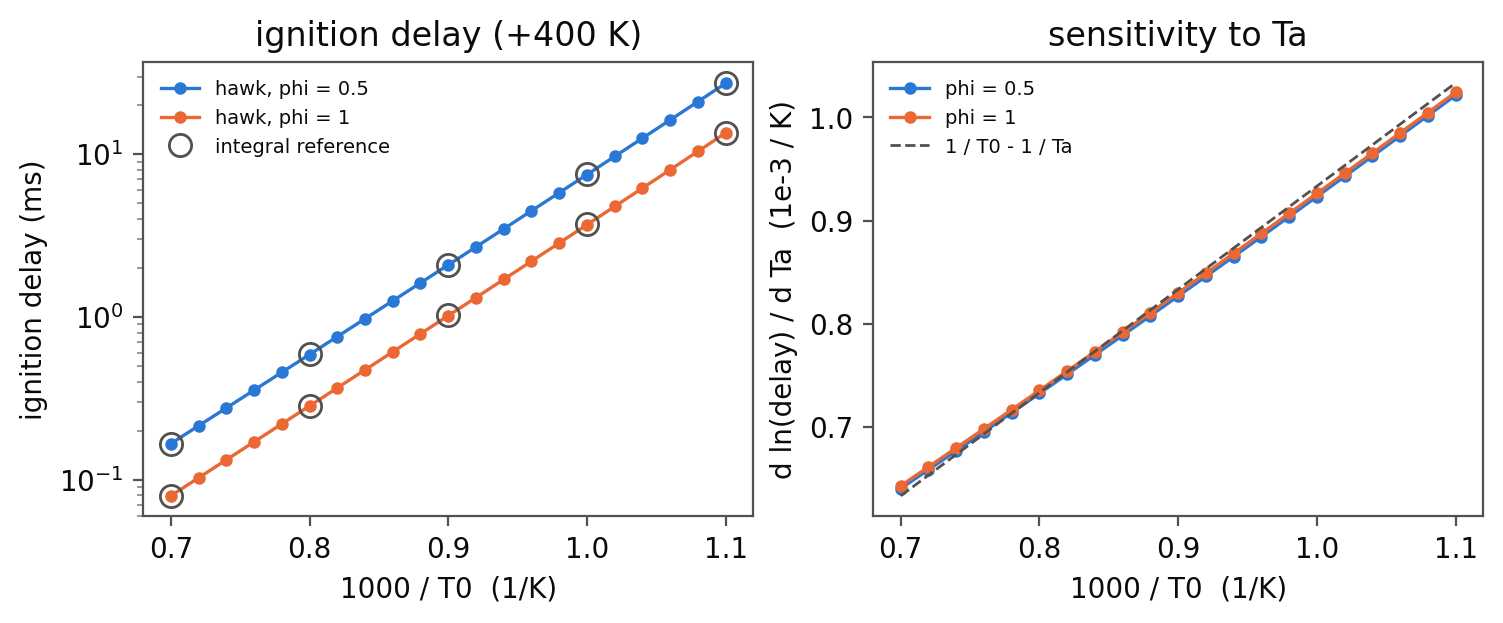
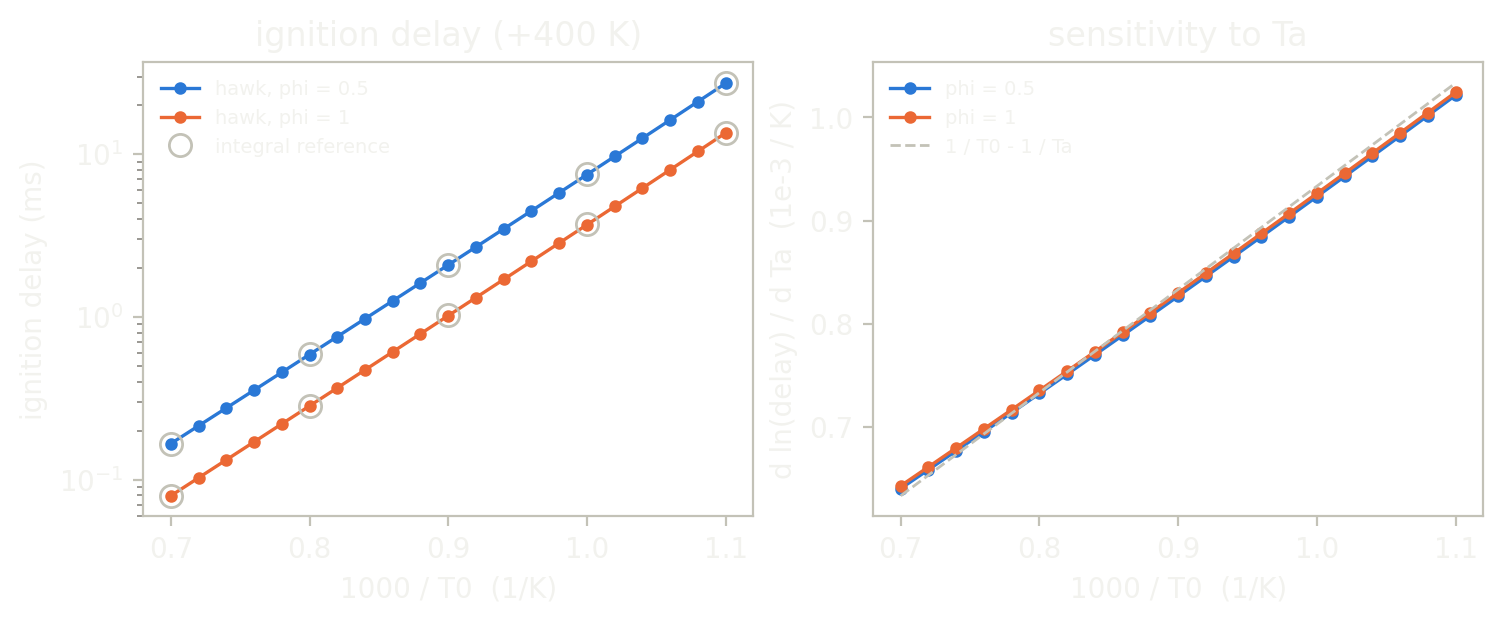

In [9]:
import matplotlib.pyplot as plt

colours = ["#2a78d6", "#eb6834"]
fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True)
for j, phi in enumerate(phis):
    lane = slice(j * len(inv_T), (j + 1) * len(inv_T))
    left.semilogy(inv_T, tau[lane] * 1e3, "o-", ms=3.5, lw=1.2, color=colours[j], label=f"hawk, phi = {phi:g}")
    right.plot(inv_T, sensitivity[lane] * 1e3, "o-", ms=3.5, lw=1.2, color=colours[j], label=f"phi = {phi:g}")
left.semilogy(1000.0 / T0[every], want[every] * 1e3, "o", ms=8, mfc="none", color="#898781", label="integral reference")
right.plot(inv_T, inv_T - 1000.0 / TA, "--", lw=1.0, color="#898781", label="1 / T0 - 1 / Ta")
left.set_xlabel("1000 / T0  (1/K)"); left.set_ylabel("ignition delay (ms)"); left.set_title("ignition delay (+400 K)")
right.set_xlabel("1000 / T0  (1/K)"); right.set_ylabel("d ln(delay) / d Ta  (1e-3 / K)"); right.set_title("sensitivity to Ta")
left.legend(frameon=False, fontsize=7); right.legend(frameon=False, fontsize=7)
show(fig, "Two panels against 1000 over the start temperature. Left: ignition delay on a log scale falls from 14 to 27 milliseconds at the coolest start to 0.08 to 0.17 milliseconds at the hottest, as two nearly straight lines for the stoichiometric and lean mixtures, with rings from the reference integral on top. Right: the sensitivity of the log delay to the activation temperature rises from about 0.64 to about 1.03 times 1e-3 per kelvin, a straight line that follows the dashed line 1 over T0 minus 1 over Ta.")

## A bigger sweep, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel and the same call run on device arrays. A fine grid of start temperatures and equivalence ratios, 200 000 lanes, ends every lane on the GPU. The first 42 lanes are the sweep above and must agree with the host run to a relative 1e-9 (devices round differently, so not bit for bit).

In [10]:
if gpu_available():
    big = 200_000
    k = np.arange(big)
    T_big = np.where(k < n, np.resize(T0, big), 900.0 + 500.0 * (k % 997) / 996.0)
    Y_big = np.where(k < n, np.resize(Y0, big), (0.5 + 0.5 * (k % 89) / 88.0) / (17.2 + 0.5 + 0.5 * (k % 89) / 88.0))
    got = reactor.run(T0=xp.asarray(T_big), Y0=xp.asarray(Y_big), A=A, Ta=TA, heat=HEAT, rise=RISE, **STEP)
    assert on_device(got["tau"]), "the result is a device array: the kernel ran on the GPU"
    first = to_numpy(got["tau"])[:n]
    assert np.allclose(first, tau, rtol=1e-9)
    print(f"{big} lanes on the GPU: every one ignited ({bool((to_numpy(got['tau']) > 0).all())}); the first {n} agree with the host run to 1e-9")
else:
    print("no GPU here; the sweep stays at", n, "lanes")

200000 lanes on the GPU: every one ignited (True); the first 42 agree with the host run to 1e-9


## The animation

The temperature traces of eight start temperatures at stoichiometric `phi`, each stopping at ignition, labelled by start temperature. The trace comes from the same kernel: asking for an ignition at a smaller rise gives the time the gas passed that temperature. That is exact because the sequence of steps does not depend on `rise`, so every run follows the same path and stops earlier or later along it. A run per threshold, from 1 K up to 400 K, draws the whole curve. A lane's line ends at the dot where it reaches +400 K. The drawing lives in a small helper shared by the domain pages; it writes a looping GIF for a light page and one for a dark page.

In [11]:
from ensemble_anim import stopping_traces

shown = np.linspace(1000.0 / 1.10, 1000.0 / 0.70, 8)                  # start temperatures, coolest first
thresholds = np.geomspace(1.0, RISE, 120)
planes = dict(T0=shown, Y0=np.full(8, phis[1] / (17.2 + phis[1])), A=A, Ta=TA, heat=HEAT, **STEP)
times = np.array([np.asarray(reactor.run(rise=r, **planes)["tau"]) for r in thresholds])        # (threshold, lane): when each lane passed it
sizes = stopping_traces(times, thresholds, [f"{T:.0f}" for T in shown], "ignition_delay", ylabel="temperature rise (K)",
                        stop_text="ignition: +400 K", count_text="still warming", key_text="labels: start temperature (K)")
for name, size in sizes.items():
    print(name, f"{size / 1e3:.0f} kB")

ignition_delay_light.gif 363 kB
ignition_delay_dark.gif 391 kB


```{image} ../../_static/anim/ignition_delay_light.gif
:class: only-light
:alt: Temperature-rise curves for eight start temperatures, coolest to hottest, growing in log time; each flattens, then climbs steeply and stops at a dot on the dashed 400 K line, the hottest first
```
```{image} ../../_static/anim/ignition_delay_dark.gif
:class: only-dark
:alt: Temperature-rise curves for eight start temperatures, coolest to hottest, growing in log time; each flattens, then climbs steeply and stops at a dot on the dashed 400 K line, the hottest first
```

## What just happened

- `Reactor` named the start state (`T0`, `Y0`), the mechanism (`A`, `Ta`, `heat`) and the stepping once; `ignite` is the whole integration, written in those names.
- Each lane integrated its chemistry with a linearised implicit step and left the loop at ignition, with the crossing time interpolated inside the last step.
- The enthalpy balance held to rounding at the stop, and a burn-out run reached the closed-form flame temperature.
- The delays agreed with the reference integral within the stated tolerance, and the error halved when `dT_step` did.
- `jvp` gave `d tau / d Ta` through the loop and the stop. It matched central differences, and the derivative of the reference integral within the scheme's error.

## Try this

Make the mixture leaner than `phi = 0.5` and watch the flame temperature fall. Or give the model a second parameter, a reaction order `n` in `dY/dt = -k Y^n`, and take its sensitivity next to the one for `Ta`. Both are small edits to the kernel; the checks above stay as they are.

## Next

[Monte Carlo](12_monte_carlo_ensemble) stops a batch of samples as each one ends. [Reverse a whole rollout](05_tapes_and_events) covers gradients through many launches rather than one.